# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

Вариант NLP, русский язык. Основная модель — `cointegrated/rubert-tiny2`,
данные — русские сплиты [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural),
лицензия CC BY-NC-SA 4.0. Модели RuBERT-tiny2 и RuBERT-tiny распространяются под MIT.
Абляция: замороженный энкодер против полного дообучения.
Выполнены разделы 1–5 и бонусы 6.2, 6.3, 6.4, 6.5; бонус 6.1 не выбран.

Полный прогон выполнен 22 ноября 2026 года с FAST_MODE=False на Tesla V100-SXM2-16GB.
Сервер: Intel Xeon E5-2698R v4, 10 vCPU, 28 GB RAM. Для CPU-замеров использованы 4 потока.
Окружение: Python 3.12.16, PyTorch 2.6.0+cu118, transformers 5.22.1, datasets 5.1.0;
остальные версии сохранены в artifacts/environment.txt. Ноутбук выполнен в новом ядре,
outputs сохранены. Численные выводы относятся к этому прогону с SEED=0.

Источники: условия этого ноутбука;
[token classification](https://huggingface.co/docs/transformers/tasks/token_classification),
[Trainer](https://huggingface.co/docs/transformers/main_classes/trainer),
[RuBERT-tiny2](https://huggingface.co/cointegrated/rubert-tiny2),
[RuBERT-tiny](https://huggingface.co/cointegrated/rubert-tiny),
[WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural),
[ONNX Runtime quantization](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html).


In [1]:
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from pathlib import Path

WORK_DIR = Path.cwd()
if not (WORK_DIR / 'hw2_nlp.ipynb').exists() and (WORK_DIR / 'HW2/hw2_nlp.ipynb').exists():
    WORK_DIR = WORK_DIR / 'HW2'
CACHE_ROOT = WORK_DIR / 'cache'
CACHE_ROOT.mkdir(exist_ok=True)
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
os.environ.setdefault('HF_HOME', str(CACHE_ROOT / 'huggingface'))
os.environ.setdefault('HF_HUB_DISABLE_IMPLICIT_TOKEN', '1')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

import collections
import copy
import hashlib
import json
import math
import random
import re
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import datasets
import transformers
from datasets import Dataset, DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from seqeval.metrics.sequence_labeling import get_entities
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

torch.set_num_threads(min(4, os.cpu_count() or 1))
transformers.logging.set_verbosity_error()
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11})
print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

/home/user/hw2-ner/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.6.0+cu118, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla V100-SXM2-16GB


In [4]:
FAST_MODE = False
SMOKE_MODE = False
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None
N_EVAL = 500 if FAST_MODE else None
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128
ARTIFACTS = WORK_DIR / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Выбран RuBERT-tiny2: русский язык, около 29.4 млн параметров в опубликованной модели, лицензия MIT. В карточке описаны дистилляция представлений LaBSE и дообучение сегментных эмбеддингов на NLI; полное описание состава корпуса там не приведено. Словарь из 83 828 сабвордов полезен для русских слов, а три слоя делают модель удобной для нескольких экспериментов на одном GPU; ожидаемое качество NER проверяется новой головой и дообучением. Для сравнения, [RuBERT-base-cased](https://huggingface.co/DeepPavlov/rubert-base-cased) из списка задания имеет около 180 млн параметров, 12 слоёв ширины 768, обучался на русской Wikipedia и новостях: его вычислительный бюджет существенно выше, но сопоставимого NER F1 карточки не дают. В бонусе также проверяется [RuBERT-tiny](https://huggingface.co/cointegrated/rubert-tiny), около 12 млн параметров, русский и английский, MIT; он обучался на Yandex Translate corpus, OPUS-100 и Tatoeba, а автор характеризует tiny2 как улучшение на русских NLU-задачах без обещания конкретного NER F1. Без фиксации revision могут измениться веса, словарь, токенизатор или конфигурация, поэтому опыт перестанет быть воспроизводимым.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 5429.98it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    backbone = model.base_model
    embeddings = backbone.embeddings
    encoder = getattr(backbone, 'encoder', None)
    if encoder is None:
        encoder = backbone.transformer
    layers = encoder.layer
    all_params = {id(p): p for p in model.parameters()}
    embedding_ids = {id(p) for p in embeddings.parameters()}
    head_ids = {id(p) for p in model.classifier.parameters()}
    encoder_ids, layer_counts = set(), []
    for layer in layers:
        ids = {id(p) for p in layer.parameters()} - encoder_ids
        layer_counts.append(sum(all_params[key].numel() for key in ids))
        encoder_ids.update(ids)
    if embedding_ids & encoder_ids or head_ids & (embedding_ids | encoder_ids):
        raise ValueError('Parameter groups overlap')
    other_ids = set(all_params) - embedding_ids - encoder_ids - head_ids
    count = lambda ids: sum(all_params[key].numel() for key in ids)
    return dict(embeddings=count(embedding_ids), encoder=count(encoder_ids),
                head=count(head_ids), other=count(other_ids), layers=layer_counts)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids:', tuple(enc['input_ids'].shape))
print('attention_mask:', tuple(enc['attention_mask'].shape))
print('hidden_states:', [tuple(h.shape) for h in out.hidden_states])
print('logits:', tuple(out.logits.shape))

input_ids: (2, 11)
attention_mask: (2, 11)
hidden_states: [(2, 11, 312), (2, 11, 312), (2, 11, 312), (2, 11, 312)]
logits: (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)


x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 2.7 ms на Tesla V100-SXM2-16GB


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Dummy-батч имеет input_ids и attention_mask формы (2,11). После эмбеддингов и каждого из трёх слоёв энкодера форма остаётся (2,11,312), поэтому hidden_states содержит четыре тензора; голова на семь демонстрационных BIO-тегов даёт logits (2,11,7). Больше всего параметров приходится на эмбеддинги: основную долю даёт таблица из 83 828 векторов ширины 312, тогда как новая NER-голова мала. Обмен информацией между токенами происходит в энкодере; lookup эмбеддингов и линейная голова работают с каждой позицией независимо. Число позиций превышает число слов из-за специальных токенов и разбиения отдельных слов на несколько сабвордов.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', 'ru'
DATASET_REVISION = '74c9b9dca034bb1606a6769457983904bd976803'
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
source_splits = {'train': 'train_ru', 'validation': 'val_ru', 'test': 'test_ru'}
data_files = {name: f'hf://datasets/{DATASET_ID}@{DATASET_REVISION}/data/{source}-00000-of-00001.parquet'
              for name, source in source_splits.items()}
raw = load_dataset('parquet', data_files=data_files, cache_dir=str(CACHE_ROOT / 'datasets'))


def deduplicate_splits(dataset_dict):
    seen, cleaned, audit = {}, {}, {}
    for name in ['train', 'validation', 'test']:
        ds = dataset_dict[name]
        keep, duplicates, conflicts, empty = [], 0, 0, 0
        for index, example in enumerate(ds):
            words, tags = example['tokens'], example['ner_tags']
            if len(words) != len(tags) or any(not 0 <= tag < len(LABEL_NAMES) for tag in tags):
                raise ValueError(f'Invalid annotation: {name}[{index}]')
            if not words:
                empty += 1
                continue
            digest = hashlib.sha256(json.dumps(words, ensure_ascii=False).encode('utf-8')).digest()
            if digest in seen:
                duplicates += 1
                conflicts += tuple(tags) != seen[digest]
            else:
                seen[digest] = tuple(tags)
                keep.append(index)
        cleaned[name] = ds.select(keep).select_columns(['tokens', 'ner_tags'])
        audit[name] = dict(before=len(ds), after=len(keep), duplicates=duplicates,
                           conflicting_duplicates=conflicts, empty=empty)
    return DatasetDict(cleaned), audit


raw, data_audit = deduplicate_splits(raw)
print('Deduplication by identical token sequences, priority: train, validation, test')
print(json.dumps(data_audit, ensure_ascii=False, indent=2))

Deduplication by identical token sequences, priority: train, validation, test
{
  "train": {
    "before": 92320,
    "after": 92320,
    "duplicates": 0,
    "conflicting_duplicates": 0,
    "empty": 0
  },
  "validation": {
    "before": 11540,
    "after": 11540,
    "duplicates": 0,
    "conflicting_duplicates": 0,
    "empty": 0
  },
  "test": {
    "before": 11580,
    "after": 11580,
    "duplicates": 0,
    "conflicting_duplicates": 0,
    "empty": 0
  }
}


train {"sentences": 92320, "entities": {"LOC": 71090, "PER": 33282, "MISC": 23594, "ORG": 20236}, "sentence_length": {"median": 17.0, "p95": 41.0, "max": 256.0}, "span_length": {"median": 1.0, "p95": 3.0, "max": 24.0}}


validation {"sentences": 11540, "entities": {"ORG": 2710, "LOC": 8851, "MISC": 2642, "PER": 4007}, "sentence_length": {"median": 17.0, "p95": 38.0, "max": 107.0}, "span_length": {"median": 1.0, "p95": 3.0, "max": 10.0}}


test {"sentences": 11580, "entities": {"LOC": 8596, "PER": 3489, "MISC": 2962, "ORG": 3051}, "sentence_length": {"median": 17.0, "p95": 38.0, "max": 124.0}, "span_length": {"median": 1.0, "p95": 3.0, "max": 13.0}}


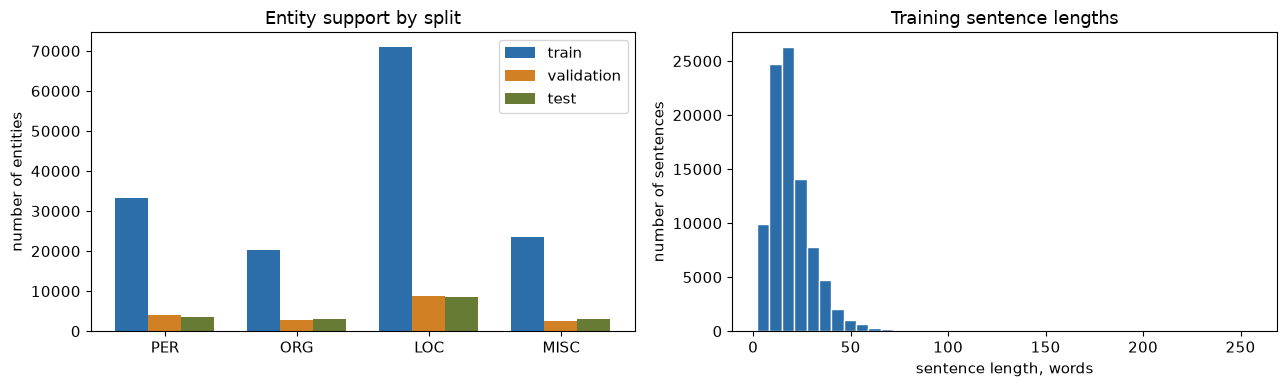

In [14]:
data_statistics = {}
for name, ds in raw.items():
    entity_counts = collections.Counter()
    sentence_lengths, span_lengths = [], []
    for example in ds:
        sentence_lengths.append(len(example['tokens']))
        for entity, start, end in get_entities([LABEL_NAMES[tag] for tag in example['ner_tags']]):
            entity_counts[entity] += 1
            span_lengths.append(end - start + 1)
    data_statistics[name] = dict(sentences=len(ds), entities=dict(entity_counts),
                                sentence_length=dict(zip(['median', 'p95', 'max'],
                                                         map(float, np.percentile(sentence_lengths, [50, 95, 100])))),
                                span_length=dict(zip(['median', 'p95', 'max'],
                                                     map(float, np.percentile(span_lengths, [50, 95, 100])))))
    print(name, json.dumps(data_statistics[name], ensure_ascii=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
types = ['PER', 'ORG', 'LOC', 'MISC']
for offset, (name, color) in enumerate(zip(raw, ['#2c6eaa', '#d18123', '#677b35'])):
    values = [data_statistics[name]['entities'].get(entity, 0) for entity in types]
    axes[0].bar(np.arange(len(types)) + offset * 0.25, values, width=0.25, label=name, color=color)
axes[0].set_xticks(np.arange(len(types)) + 0.25, types)
axes[0].set_ylabel('number of entities')
axes[0].set_title('Entity support by split')
axes[0].legend()
lengths = [len(words) for words in raw['train']['tokens']]
axes[1].hist(lengths, bins=40, color='#2c6eaa', edgecolor='white')
axes[1].set_xlabel('sentence length, words')
axes[1].set_ylabel('number of sentences')
axes[1].set_title('Training sentence lengths')
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** WikiNEuRal — автоматически размеченные тексты Wikipedia, лицензия CC BY-NC-SA 4.0. Русские train_ru, val_ru и test_ru содержат 92 320, 11 540 и 11 580 предложений; пустых предложений и точных повторов проверка не нашла. В train насчитано 71 090 LOC, 33 282 PER, 23 594 MISC и 20 236 ORG, то есть ORG здесь самый редкий тип. Медиана длины предложения равна 17 словам, медиана спана — одному слову, а 95-й процентиль длины спана — трём; при этом встречаются существенно более длинные примеры, поэтому обрезку проверяем отдельно. Автоматическая разметка может пропускать сущности и давать спорные типы; ошибку относительно корпуса нужно отличать от семантической ошибки модели.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    result, start, entity = [], None, None
    for index, tag in enumerate(list(tags) + ['O']):
        if tag == 'O':
            prefix, kind = 'O', None
        else:
            if not isinstance(tag, str) or '-' not in tag:
                raise ValueError(f'Invalid BIO tag: {tag!r}')
            prefix, kind = tag.split('-', 1)
            if prefix not in {'B', 'I'} or not kind:
                raise ValueError(f'Invalid BIO tag: {tag!r}')
        continues = prefix == 'I' and start is not None and kind == entity
        if start is not None and not continues:
            result.append((start, index, entity))
            start, entity = None, None
        if prefix in {'B', 'I'} and not continues:
            start, entity = index, kind
    return result


def spans_to_bio(spans, n_words):
    if n_words < 0:
        raise ValueError('n_words must be nonnegative')
    tags = ['O'] * n_words
    for start, end, entity in sorted(spans):
        if not 0 <= start < end <= n_words or not isinstance(entity, str) or not entity:
            raise ValueError('Invalid span')
        if any(tag != 'O' for tag in tags[start:end]):
            raise ValueError('Overlapping spans cannot be represented in BIO')
        tags[start:end] = [f'B-{entity}'] + [f'I-{entity}'] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    result, seen = [], set()
    for word in word_ids:
        if word is None:
            result.append(-100)
            continue
        if not 0 <= word < len(word_labels):
            raise ValueError('word_id is outside the annotation')
        label = word_labels[word]
        if word not in seen:
            result.append(label)
            seen.add(word)
        else:
            result.append(-100 if b_to_i is None else b_to_i.get(label, label))
    return result

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]
print('ok')

ok


In [17]:
def write_span_jsonl(dataset, path, label_names):
    path.parent.mkdir(parents=True, exist_ok=True)
    changed = 0
    with path.open('w', encoding='utf-8') as stream:
        for example in dataset:
            tags = [label_names[index] for index in example['ner_tags']]
            spans = bio_to_spans(tags)
            changed += spans_to_bio(spans, len(tags)) != tags
            record = dict(tokens=example['tokens'], spans=spans)
            stream.write(json.dumps(record, ensure_ascii=False) + '\n')
    return changed


def read_span_jsonl(path, label_names):
    tag_ids = {tag: index for index, tag in enumerate(label_names)}
    records = []
    with path.open(encoding='utf-8') as stream:
        for line in stream:
            record = json.loads(line)
            tags = spans_to_bio(record['spans'], len(record['tokens']))
            records.append(dict(tokens=record['tokens'], ner_tags=[tag_ids[tag] for tag in tags]))
    return Dataset.from_list(records)


conversion_audit, restored = {}, {}
for name, ds in raw.items():
    path = WORK_DIR / 'data' / f'{name}_spans.jsonl'
    changed = write_span_jsonl(ds, path, LABEL_NAMES)
    back = read_span_jsonl(path, LABEL_NAMES)
    for before, after in zip(ds, back):
        if before['tokens'] != after['tokens']:
            raise AssertionError('Tokens changed during round trip')
        spans_before = bio_to_spans([LABEL_NAMES[i] for i in before['ner_tags']])
        spans_after = bio_to_spans([LABEL_NAMES[i] for i in after['ner_tags']])
        if spans_before != spans_after:
            raise AssertionError('Entity spans changed during round trip')
    restored[name] = back
    conversion_audit[name] = dict(sentences=len(back), normalized_bio_sentences=changed)
raw = DatasetDict(restored)
print('BIO → JSON spans → BIO:', conversion_audit)

BIO → JSON spans → BIO: {'train': {'sentences': 92320, 'normalized_bio_sentences': 3210}, 'validation': {'sentences': 11540, 'normalized_bio_sentences': 393}, 'test': {'sentences': 11580, 'normalized_bio_sentences': 464}}


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)


n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')
alignment_audit = dict(sentences=len(data['train']), at_length_limit=n_truncated,
                       actually_truncated=0, words_without_subwords=0, words_dropped_by_truncation=0)
for example in data['train']:
    complete = tokenizer(example['tokens'], is_split_into_words=True, truncation=False)
    clipped = tokenizer(example['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    all_words = set(complete.word_ids()) - {None}
    kept_words = set(clipped.word_ids()) - {None}
    alignment_audit['actually_truncated'] += len(complete['input_ids']) > MAX_LENGTH
    alignment_audit['words_without_subwords'] += len(example['tokens']) - len(all_words)
    alignment_audit['words_dropped_by_truncation'] += len(all_words - kept_words)
print('Alignment audit:', alignment_audit)

Map:   0%|          | 0/92320 [00:00<?, ? examples/s]

Map:   1%|          | 1000/92320 [00:00<00:10, 8337.75 examples/s]

Map:   2%|▏         | 2000/92320 [00:00<00:11, 8188.81 examples/s]

Map:   3%|▎         | 3000/92320 [00:00<00:11, 8062.58 examples/s]

Map:   4%|▍         | 4000/92320 [00:00<00:10, 8203.16 examples/s]

Map:   5%|▌         | 5000/92320 [00:00<00:10, 8352.89 examples/s]

... (113 outputs left out)

Map: 100%|██████████| 11580/11580 [00:01<00:00, 7477.06 examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 92320
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 11580
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']


train: проверено 92236 предложений, обрезано по MAX_LENGTH 83, слов без сабвордов или за обрезкой 2196
[CLS]            None  -100
Детство             0  O
провёл              1  O
в                   2  O
Над                 3  B-LOC
##ь                 3  -100
##сом               3  -100
##бат               3  -100
##е                 3  -100
,                   4  O
с                   5  O
1860                6  O
г                   7  O
.                   8  O
[SEP]            None  -100


Alignment audit: {'sentences': 92320, 'at_length_limit': 83, 'actually_truncated': 78, 'words_without_subwords': 12, 'words_dropped_by_truncation': 2184}


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метка на первом сабворде даёт каждому слову один вклад в cross-entropy;
-100 исключает продолжения слова и специальные токены из loss. Из 92 320 train-предложений
лимит длины достигнут в 83, а действительно обрезаны 78: это разные события.
За обрезкой потеряно 2 184 слова, ещё 12 слов не получили сабвордов; при оценке им
назначается O, поэтому сущности в таких позициях могут снижать recall.
В JSON правая граница спана не включается. При обратной конвертации нормализованы
одинокие I-теги в 3 210 train, 393 validation и 464 test-предложениях, но сами спаны
и токены во всех примерах сохранились. Это проверено полным проходом по трём сплитам;
пересекающиеся спаны не возникают, так как исходная разметка уже дана в BIO.


---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):

    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    if len(tokens_list) != len(tags_list):
        raise ValueError('Different number of sentences')
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        if len(words) != len(tags):
            raise ValueError('Different number of words and tags')
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: values.most_common(1)[0][0] for word, values in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority_tagger = fit_majority_tagger(data['train']['tokens'], train_tags)
majority_pred = [predict_majority(majority_tagger, words) for words in val_tokens]
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline['majority'] = entity_scores(val_gold, majority_pred)
baseline['random_head'] = entity_scores(val_gold, random_pred)
random_model.cpu()
del random_model
print(json.dumps(baseline, indent=2))

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 3740.50it/s]

{
  "majority": {
    "f1_micro": 0.5839363458940099,
    "f1_macro": 0.5083306497472486,
    "precision": 0.6441868168267638,
    "recall": 0.5339923119165294
  },
  "random_head": {
    "f1_micro": 0.029393424222334538,
    "f1_macro": 0.028270139891322568,
    "precision": 0.016691889635223688,
    "recall": 0.12295442064799561
  }
}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** На validation словарный бейзлайн получил entity micro-F1
58.39%, а энкодер со случайной головой —
2.94%. Повторяющиеся названия позволяют словарю
давать осмысленный результат, но он не учитывает контекст, сохраняет регистр,
а незнакомым словам назначает O. При равных частотах выбирается первый встретившийся тег.
У случайной головы precision всего 1.67%:
она ещё не связывает признаки предобученного энкодера с нужными BIO-тегами и создаёт
много лишних сущностей. Само предобучение не заменяет обучение NER-головы.


---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer
    for parameter in model.parameters():
        parameter.requires_grad_(True)
    if freeze_encoder:
        for parameter in model.base_model.parameters():
            parameter.requires_grad_(False)
    steps = math.ceil(len(train_ds) / batch_size) * epochs
    interval = max(1, int(steps // 12))
    arguments = TrainingArguments(
        output_dir=str(WORK_DIR / out_dir), num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=batch_size,
        warmup_steps=math.ceil(steps * 0.1), weight_decay=0.01, lr_scheduler_type='linear',
        optim='adamw_torch', eval_strategy='steps', eval_steps=interval,
        logging_strategy='steps', logging_steps=interval, logging_first_step=True,
        save_strategy='no', report_to='none', prediction_loss_only=True,
        use_cpu=device.type == 'cpu', fp16=device.type == 'cuda', bf16=False,
        dataloader_num_workers=0, dataloader_pin_memory=device.type == 'cuda',
        seed=SEED, data_seed=SEED, disable_tqdm=True,
    )
    collator = DataCollatorForTokenClassification(tok, pad_to_multiple_of=8 if device.type == 'cuda' else None)
    trainer = Trainer(model=model, args=arguments, train_dataset=train_ds, eval_dataset=eval_ds,
                      processing_class=tok, data_collator=collator)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    started = time.perf_counter()
    trainer.train()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    seconds = time.perf_counter() - started
    model.eval()
    model.zero_grad(set_to_none=True)
    return [dict(row) for row in trainer.state.log_history], seconds

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 5561.21it/s]

{'loss': '2.09', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.0003466'}


{'loss': '0.3266', 'grad_norm': '0.9653', 'learning_rate': '0.0001661', 'epoch': '0.2499'}


{'eval_loss': '0.08651', 'eval_runtime': '2.957', 'eval_samples_per_second': '3903', 'eval_steps_per_second': '122.1', 'epoch': '0.2499'}


{'loss': '0.08305', 'grad_norm': '0.686', 'learning_rate': '0.0001853', 'epoch': '0.4998'}


... (18 outputs left out)

{'eval_loss': '0.06613', 'eval_runtime': '2.854', 'eval_samples_per_second': '4044', 'eval_steps_per_second': '126.5', 'epoch': '2.749'}


{'loss': '0.01765', 'grad_norm': '0.2981', 'learning_rate': '1.284e-07', 'epoch': '2.999'}


{'eval_loss': '0.06641', 'eval_runtime': '2.986', 'eval_samples_per_second': '3865', 'eval_steps_per_second': '120.9', 'epoch': '2.999'}


{'eval_loss': '0.06641', 'eval_runtime': '2.963', 'eval_samples_per_second': '3895', 'eval_steps_per_second': '121.8', 'epoch': '3'}
{'train_runtime': '224', 'train_samples_per_second': '1236', 'train_steps_per_second': '38.64', 'train_loss': '0.06481', 'epoch': '3'}
обучение: 224.2 c на Tesla V100-SXM2-16GB, 92320 предложений, 3 эпох(а)


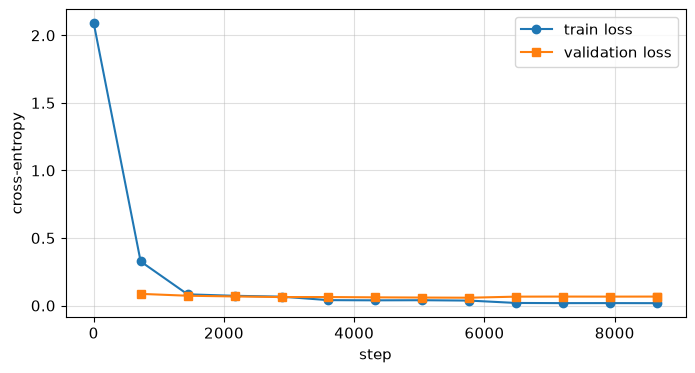

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** У модели всего три слоя, поэтому выбрал lr=2e-4,
выше типичного значения для base-энкодеров; batch size=32 помещается в память V100.
Бюджет — 3 эпохи, warmup 10% шагов, затем линейное снижение learning rate,
weight decay=0.01 и fp16. Параметры были зафиксированы до оценки на test.
Обучение заняло 224.2 с на Tesla V100-SXM2-16GB.
Validation loss достиг минимума 0.0580 около эпохи
2.00, а к концу вырос до 0.0664, хотя
последний train loss снизился до 0.0176.
На третьей эпохе видны признаки переобучения; дальше я бы проверил раннюю остановку
по validation, а не просто увеличивал число эпох.


## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    if len(gold) != len(pred):
        raise ValueError('Different number of sentences')
    correct = predicted = actual = 0
    for gold_tags, pred_tags in zip(gold, pred):
        if len(gold_tags) != len(pred_tags):
            raise ValueError('Different sentence lengths')
        for truth, guess in zip(gold_tags, pred_tags):
            actual += truth != 'O'
            predicted += guess != 'O'
            correct += truth == guess and truth != 'O'
    return 2 * correct / (actual + predicted) if actual + predicted else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9
assert abs(f1_score(g, p) - 0.5) < 1e-9
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

final = {}
val_pred = []
val_pred, val_probs = predict_word_tags(model, val_tokens, return_probs=True)
validation_scores = entity_scores(val_gold, val_pred)
validation_scores['token_f1'] = token_f1(val_gold, val_pred)
validation_report = classification_report(val_gold, val_pred, output_dict=True, zero_division=0)
print('VALIDATION')
print(classification_report(val_gold, val_pred, digits=4, zero_division=0))
test_tokens = [list(words) for words in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred, test_probs = predict_word_tags(model, test_tokens, return_probs=True)
test_report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final.update(entity_scores(test_gold, test_pred))
final['token_f1'] = token_f1(test_gold, test_pred)
final['per_type'] = {name: test_report[name] for name in ENTITY_TYPES if name in test_report}
print('TEST')
print(classification_report(test_gold, test_pred, digits=4, zero_division=0))
print('Token F1:', final['token_f1'])

VALIDATION


              precision    recall  f1-score   support

         LOC     0.9141    0.9181    0.9161      8851
        MISC     0.7238    0.7358    0.7297      2642
         ORG     0.7469    0.7982    0.7717      2710
         PER     0.8624    0.8840    0.8731      4007

   micro avg     0.8491    0.8663    0.8576     18210
   macro avg     0.8118    0.8340    0.8226     18210
weighted avg     0.8502    0.8663    0.8581     18210



TEST


              precision    recall  f1-score   support

         LOC     0.9231    0.9244    0.9237      8596
        MISC     0.7422    0.7620    0.7520      2962
         ORG     0.7493    0.8073    0.7772      3051
         PER     0.8599    0.9008    0.8799      3489

   micro avg     0.8504    0.8735    0.8618     18098
   macro avg     0.8186    0.8486    0.8332     18098
weighted avg     0.8520    0.8735    0.8625     18098

Token F1: 0.8796166575297963


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На test entity micro-F1 равен 86.18%,
macro-F1 — 83.32%, токенный F1 — 87.96%.
Хуже всего MISC: F1 75.20% при support
2962; лучше всего LOC —
92.37% при support 8596.
MISC объединяет разнородные названия, а граница с PER и ORG зависит от контекста
и качества автоматической разметки; одной редкостью это не объяснить,
поскольку в train ORG встречается ещё реже.
Micro-F1 выше macro-F1, так как частый LOC распознаётся лучше редких типов.
Токенный F1 выше entity-F1 на 1.78 п.п.:
он засчитывает правильно размеченные части сущностей даже при ошибке границы.
Для извлечения готовых названий полезнее entity-F1 с точными границами и типом.


---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    gold_spans = [tuple(span) for span in gold_spans]
    pred_spans = [tuple(span) for span in pred_spans]
    result = []

    def overlaps(a, b):
        return max(a[0], b[0]) < min(a[1], b[1])

    def overlap_score(a, b):
        intersection = min(a[1], b[1]) - max(a[0], b[0])
        union = max(a[1], b[1]) - min(a[0], b[0])
        return (intersection / union, intersection, -abs(a[0] - b[0]) - abs(a[1] - b[1]), -b[0], -b[1])

    for gold in gold_spans:
        candidates = [pred for pred in pred_spans if overlaps(gold, pred)]
        if gold in candidates:
            result.append(('correct', gold, gold))
        else:
            same_type = [pred for pred in candidates if pred[2] == gold[2]]
            if same_type:
                result.append(('boundary', gold, max(same_type, key=lambda pred: overlap_score(gold, pred))))
            elif candidates:
                result.append(('type', gold, max(candidates, key=lambda pred: overlap_score(gold, pred))))
            else:
                result.append(('missed', gold, None))
    result.extend(('spurious', None, pred) for pred in pred_spans
                  if not any(overlaps(gold, pred) for gold in gold_spans))
    return result

Counts: {'correct': 15775, 'boundary': 670, 'type': 1378, 'missed': 387, 'spurious': 623}
Shares among errors: {'boundary': 0.2191, 'type': 0.4506, 'missed': 0.1266, 'spurious': 0.2037}
missed Течёт с северо-запада на юго-восток в пределах территории Украины и Молдавии , в том числе по территории , подконтрольной непризнанной ПМР .
  gold: (20, 21, 'LOC') prediction: None
spurious С 1979 года на Украине лесосплав на реках запрещен , что закреплено в Водном кодексе Украины ( 1995 ) , ст .
  gold: None prediction: (13, 15, 'MISC')
missed Веспрем стал одной из первых епископских кафедр Венгрии , кафедра основана в 1009 году .
  gold: (0, 1, 'LOC') prediction: None
missed Семейство Маревые выделяется в системе Кронквиста и многих других классификациях растений .
  gold: (1, 2, 'LOC') prediction: None
type Героями мультсериала являются циничная девочка Мэнди , жизнерадостный дурачок Билли , и Смерть ( Грим ) .
  gold: (12, 13, 'MISC') prediction: (12, 13, 'PER')
type Вокруг щита воротник Др

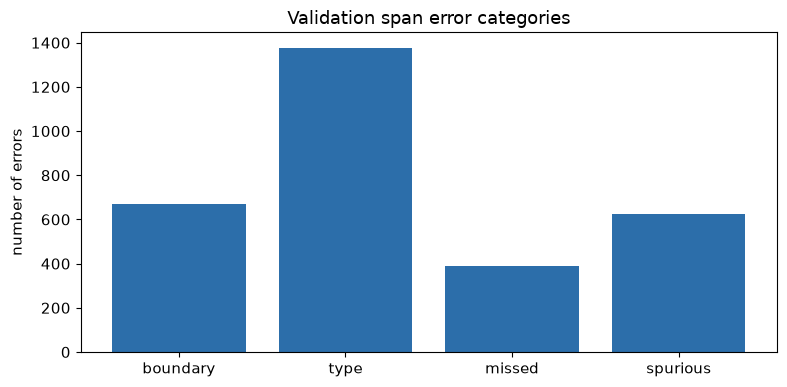

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']

errors = {}
counts = collections.Counter()
error_examples = []
by_category = collections.Counter()
for words, truth, guess in zip(val_tokens, val_gold, val_pred):
    categories = categorize_errors(bio_to_spans(truth), bio_to_spans(guess))
    for category, gold_span, pred_span in categories:
        counts[category] += 1
        if category != 'correct' and by_category[category] < 3:
            error_examples.append(dict(category=category, tokens=words, gold=gold_span, predicted=pred_span))
            by_category[category] += 1
errors = {category: counts[category] for category in ERROR_CATEGORIES}
error_total = sum(value for category, value in errors.items() if category != 'correct')
print('Counts:', errors)
print('Shares among errors:', {k: round(v / max(error_total, 1), 4) for k, v in errors.items() if k != 'correct'})
for example in error_examples:
    print(example['category'], ' '.join(example['tokens']))
    print('  gold:', example['gold'], 'prediction:', example['predicted'])

categories = [name for name in ERROR_CATEGORIES if name != 'correct']
plt.figure(figsize=(8, 4))
plt.bar(categories, [errors[name] for name in categories], color='#2c6eaa')
plt.ylabel('number of errors')
plt.title('Validation span error categories')
plt.tight_layout()
plt.show()

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Чаще всего встречается ошибка типа: 1378
случаев, 45.06% всех ошибок.
Остальные категории: boundary 670, missed 387,
spurious 623; выше показаны 12 примеров с контекстом и спанами.
У пропусков видны короткие названия вроде «ПМР» и «Веспрем».
В ошибках типа «Смерть» как персонаж получила PER вместо MISC, а название государства
«У.» было принято за имя человека. У ошибок границы показательно объединение
«Университета Питтсбурга», тогда как корпус задаёт два отдельных LOC-спана.
Среди лишних спанов есть «Водном кодексе» и одиночные общеупотребительные слова.
Некоторые метки спорные: в контексте «Семейство Маревые» gold LOC выглядит ошибкой
автоматической разметки, а LOC для «Университета» требует ручной проверки.
Для уменьшения ошибок типа я бы сначала просмотрел такие случаи и отдельно проверил
различение MISC, ORG и PER на согласованной ручной выборке.
Категории следуют приоритету из задания: один широкий predicted-спан может объяснять
несколько gold-спанов, поэтому их суммы не равны TP/FP/FN из seqeval.


## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'
set_seed(SEED)
ablation_model = make_model()
ablation_history, ablation_seconds = train_ner(
    ablation_model, tokenized['train'], tokenized['validation'],
    freeze_encoder=True, out_dir='runs/freeze')
ablation_pred = predict_word_tags(ablation_model, val_tokens)
ablation = dict(
    setting=ABLATION, evaluation_split='validation',
    full=dict(scores=validation_scores, seconds=train_seconds,
              trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)),
    freeze=dict(scores=entity_scores(val_gold, ablation_pred), seconds=ablation_seconds,
                trainable_params=sum(p.numel() for p in ablation_model.parameters() if p.requires_grad)),
    history=ablation_history,
)
RUN_TIMES['train_freeze_sec'] = ablation_seconds
ablation_model.cpu()
del ablation_model
print(json.dumps({k: v for k, v in ablation.items() if k != 'history'}, indent=2))

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 53/53 [00:00<00:00, 5641.37it/s]

{'loss': '2.09', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.0003466'}


{'loss': '1.016', 'grad_norm': '0.4996', 'learning_rate': '0.0001661', 'epoch': '0.2499'}


{'eval_loss': '0.3126', 'eval_runtime': '2.892', 'eval_samples_per_second': '3990', 'eval_steps_per_second': '124.8', 'epoch': '0.2499'}


{'loss': '0.2563', 'grad_norm': '0.226', 'learning_rate': '0.0001853', 'epoch': '0.4998'}


... (19 outputs left out)

{'loss': '0.166', 'grad_norm': '0.1634', 'learning_rate': '1.284e-07', 'epoch': '2.999'}


{'eval_loss': '0.1481', 'eval_runtime': '2.905', 'eval_samples_per_second': '3973', 'eval_steps_per_second': '124.3', 'epoch': '2.999'}


{'eval_loss': '0.1481', 'eval_runtime': '2.909', 'eval_samples_per_second': '3968', 'eval_steps_per_second': '124.1', 'epoch': '3'}
{'train_runtime': '137', 'train_samples_per_second': '2022', 'train_steps_per_second': '63.19', 'train_loss': '0.2512', 'epoch': '3'}


{
  "setting": "freeze",
  "evaluation_split": "validation",
  "full": {
    "scores": {
      "f1_micro": 0.8575933023458099,
      "f1_macro": 0.8226329918983852,
      "precision": 0.8490769147962753,
      "recall": 0.8662822624931357,
      "token_f1": 0.8719570554700179
    },
    "seconds": 224.2367944270004,
    "trainable_params": 29098929
  },
  "freeze": {
    "scores": {
      "f1_micro": 0.6313231370684417,
      "f1_macro": 0.5372011259156857,
      "precision": 0.6082353539980658,
      "recall": 0.6562328390993959
    },
    "seconds": 137.28714483800013,
    "trainable_params": 2817
  }
}


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Полное дообучение даёт validation F1
85.76% за 224.2 с, заморозка энкодера —
63.13% за 137.3 с.
Заморозка сокращает время на 38.8%,
но теряет 22.63 п.п. F1.
Обучается только 2,817 параметров вместо
29,098,929; предобученные признаки полезны,
но без их адаптации одной линейной головы недостаточно.
Сохранены те же сплиты, seed, начальная голова и гиперпараметры, меняется только
freeze_encoder. Для надёжности я бы повторил оба варианта с несколькими seed;
отдельный подбор learning rate для головы был бы уже другим экспериментом.


## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** RuBERT-tiny2 после трёх эпох на 92 320 предложениях
получил validation entity F1 85.76% и test F1
86.18%; обучение на V100 заняло 224.2 с.
На validation результат выше словарного бейзлайна на
27.37 п.п., а test token F1
87.96% показывает, что отдельные слова распознаются лучше целых спанов.
LOC даётся лучше всего, а MISC остаётся самым трудным типом с test F1
75.20%.
Заморозка энкодера сокращает время до 137.3 с, но снижает
validation F1 до 63.13%, поэтому для этого корпуса
полное дообучение оказалось полезным.
Главная категория ошибок — неверный тип, 1378 случаев на validation,
причём часть просмотренных gold-меток сама выглядит спорной.
На третьей эпохе validation loss растёт при снижении train loss, поэтому
увеличение бюджета без ранней остановки выглядит неоправданным.
Следующие проверки — несколько seed, ручная проверка спорной разметки и другой домен:
нынешние выводы ограничены Wikipedia, автоматическими метками и длиной 128 сабвордов.


### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural/ru", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 92320, "n_val": 11540, "n_test": 11580, "params_total": 29098929, "ablation": {"setting": "freeze", "evaluation_split": "validation", "full": {"scores": {"f1_micro": 0.8575933023458099, "f1_macro": 0.8226329918983852, "precision": 0.8490769147962753, "recall": 0.8662822624931357, "token_f1": 0.8719570554700179}, "seconds": 224.2367944270004, "trainable_params": 29098929}, "freeze": {"scores": {
final F1 micro 0.8618


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:

    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Бонус 6.1 не выбран; дополнительная ручная разметка не выполнялась.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    ALT_MODEL_ID = 'cointegrated/rubert-tiny'
    ALT_REVISION = '5441c5ea8026d4f6d7505ec004845409f1259fb1'
    alt_tokenizer = AutoTokenizer.from_pretrained(ALT_MODEL_ID, revision=ALT_REVISION)
    assert alt_tokenizer.is_fast
    alt_tokenized = data.map(tokenize_and_align, batched=True,
                             remove_columns=data['train'].column_names, fn_kwargs=dict(tok=alt_tokenizer))
    set_seed(SEED)
    alt_model = make_model(ALT_MODEL_ID, ALT_REVISION)
    alt_history, alt_seconds = train_ner(alt_model, alt_tokenized['train'], alt_tokenized['validation'],
                                       tok=alt_tokenizer, out_dir='runs/alternative')
    alt_pred = predict_word_tags(alt_model, val_tokens, tok=alt_tokenizer)
    model_comparison = dict(evaluation_split='validation',
        main=dict(model=MODEL_ID, scores=validation_scores, train_seconds=train_seconds,
                  params=sum(p.numel() for p in model.parameters())),
        alternative=dict(model=ALT_MODEL_ID, revision=ALT_REVISION, scores=entity_scores(val_gold, alt_pred),
                         train_seconds=alt_seconds, params=sum(p.numel() for p in alt_model.parameters())))
    timing_words = val_tokens[:min(32, len(val_tokens))]
    for name, candidate, tok in [('main', model, tokenizer), ('alternative', alt_model, alt_tokenizer)]:
        batch = tok(timing_words, is_split_into_words=True, padding=True, truncation=True,
                    max_length=MAX_LENGTH, return_tensors='pt').to(device)
        candidate.to(device).eval()
        with torch.inference_mode():
            for _ in range(3):
                candidate(**batch)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            started = time.perf_counter()
            for _ in range(10):
                candidate(**batch)
            if device.type == 'cuda':
                torch.cuda.synchronize()
        model_comparison[name]['forward_ms'] = (time.perf_counter() - started) * 1000 / 10
        lengths = [len(tok(words, is_split_into_words=True)['input_ids']) for words in val_tokens]
        model_comparison[name]['truncated_validation_sentences'] = sum(length > MAX_LENGTH for length in lengths)
    alt_model.cpu()
    del alt_model
    RUN_TIMES['train_alternative_sec'] = alt_seconds
    print(json.dumps(model_comparison, indent=2))

Map:   0%|          | 0/92320 [00:00<?, ? examples/s]

Map:   1%|          | 1000/92320 [00:00<00:12, 7054.69 examples/s]

Map:   2%|▏         | 2000/92320 [00:00<00:12, 7171.58 examples/s]

Map:   3%|▎         | 3000/92320 [00:00<00:12, 7117.15 examples/s]

Map:   4%|▍         | 4000/92320 [00:00<00:12, 7198.15 examples/s]

Map:   5%|▌         | 5000/92320 [00:00<00:11, 7339.07 examples/s]

... (139 outputs left out)

{'loss': '0.0321', 'grad_norm': '0.3569', 'learning_rate': '1.284e-07', 'epoch': '2.999'}


{'eval_loss': '0.06274', 'eval_runtime': '3.062', 'eval_samples_per_second': '3769', 'eval_steps_per_second': '117.9', 'epoch': '2.999'}


{'eval_loss': '0.06274', 'eval_runtime': '3.168', 'eval_samples_per_second': '3643', 'eval_steps_per_second': '113.9', 'epoch': '3'}
{'train_runtime': '218.3', 'train_samples_per_second': '1269', 'train_steps_per_second': '39.64', 'train_loss': '0.07781', 'epoch': '3'}


{
  "evaluation_split": "validation",
  "main": {
    "model": "cointegrated/rubert-tiny2",
    "scores": {
      "f1_micro": 0.8575933023458099,
      "f1_macro": 0.8226329918983852,
      "precision": 0.8490769147962753,
      "recall": 0.8662822624931357,
      "token_f1": 0.8719570554700179
    },
    "train_seconds": 224.2367944270004,
    "params": 29098929,
    "forward_ms": 4.37765470001068,
    "truncated_validation_sentences": 7
  },
  "alternative": {
    "model": "cointegrated/rubert-tiny",
    "revision": "5441c5ea8026d4f6d7505ec004845409f1259fb1",
    "scores": {
      "f1_micro": 0.8445242174539718,
      "f1_macro": 0.8071969849938515,
      "precision": 0.8365389795808416,
      "recall": 0.8526633717737507
    },
    "train_seconds": 218.60674873900007,
    "params": 11689329,
    "forward_ms": 4.363560900037555,
    "truncated_validation_sentences": 30
  }
}


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** При одном протоколе RuBERT-tiny2 получил validation
F1 85.76%, RuBERT-tiny —
84.45%; обучение заняло 224.2
и 218.6 с соответственно.
У моделей 29,098,929 и 11,689,329 параметров, то есть только веса
в FP32 занимают примерно 111.0 и
44.6 MiB без активаций и оптимизатора; пик GPU-памяти
отдельно не измерялся.
Средний forward на одном наборе из 32 текстов после прогрева —
4.38 против 4.36 мс на V100.
Сплиты, seed, batch size, lr, эпохи и лимит длины одинаковы, но свои токенизаторы
дают разное разбиение: обрезаны 7 и
30 validation-предложений.
Поэтому число параметров само по себе не определяет скорость: важны длина
последовательности и вычисления в энкодере. Это сравнение при фиксированном бюджете,
а не отдельный поиск лучших гиперпараметров для каждой модели.


## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

{
  "clean": {
    "f1_micro": 0.8575933023458099,
    "f1_macro": 0.8226329918983852,
    "precision": 0.8490769147962753,
    "recall": 0.8662822624931357,
    "token_f1": 0.8719570554700179
  },
  "lower": {
    "f1_micro": 0.21012127666884253,
    "f1_macro": 0.21119435354434654,
    "precision": 0.28062769569606316,
    "recall": 0.16792970895112574,
    "changed_word_fraction": 0.15264876532391222
  },
  "upper": {
    "f1_micro": 0.042942242942242935,
    "f1_macro": 0.042247984518988715,
    "precision": 0.04063725490196078,
    "recall": 0.04552443712246019,
    "changed_word_fraction": 0.7612144748129768
  },
  "typos": {
    "f1_micro": 0.8342379504993487,
    "f1_macro": 0.7971282572140285,
    "precision": 0.8246592982079622,
    "recall": 0.844041735310269,
    "changed_word_fraction": 0.08428728242120119
  }
}


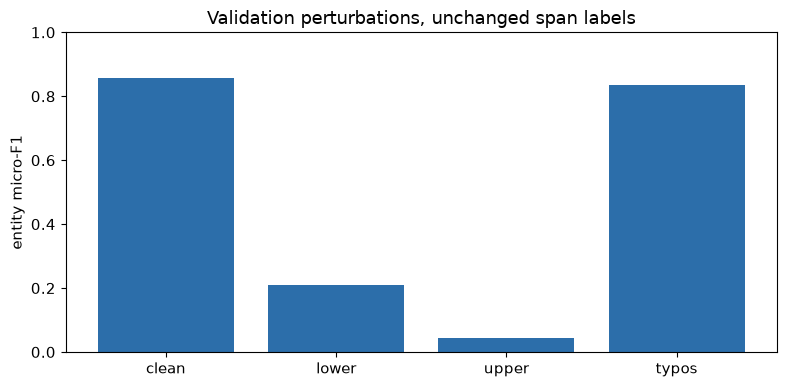

In [32]:
if '6.3' in BONUS_TASKS:
    def corrupt_tokens(tokens_list, kind, seed=0):
        rng = random.Random(seed)
        result = []
        for words in tokens_list:
            sentence = []
            for word in words:
                if kind == 'lower':
                    changed = word.lower()
                elif kind == 'upper':
                    changed = word.upper()
                elif kind == 'typos':
                    changed = word
                    if word.isalpha() and len(word) >= 4 and rng.random() < 0.15:
                        index = rng.randrange(1, len(word) - 2)
                        chars = list(word)
                        chars[index], chars[index + 1] = chars[index + 1], chars[index]
                        changed = ''.join(chars)
                else:
                    raise ValueError('Unknown corruption')
                sentence.append(changed)
            result.append(sentence)
        return result

    shift_results = {'clean': validation_scores}
    for kind in ['lower', 'upper', 'typos']:
        changed = corrupt_tokens(val_tokens, kind, SEED)
        guesses = predict_word_tags(model, changed)
        changed_words = sum(a != b for xs, ys in zip(val_tokens, changed) for a, b in zip(xs, ys))
        word_count = sum(map(len, val_tokens))
        shift_results[kind] = dict(**entity_scores(val_gold, guesses),
                                   changed_word_fraction=changed_words / max(word_count, 1))
    print(json.dumps(shift_results, indent=2))
    plt.figure(figsize=(8, 4))
    plt.bar(list(shift_results), [row['f1_micro'] for row in shift_results.values()], color='#2c6eaa')
    plt.ylim(0, 1)
    plt.ylabel('entity micro-F1')
    plt.title('Validation perturbations, unchanged span labels')
    plt.tight_layout()
    plt.show()

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** На чистом validation F1 85.76%;
нижний регистр — 21.01%; верхний регистр — 4.29%; опечатки — 83.42%.
Самое сильное падение дал вариант «верхний регистр»:
81.47 п.п.
Модель чувствительна к форме написания: регистр служит признаком названия,
а изменение букв и регистра меняет разбиение на сабворды.
Локальная проверка токенизатора: «Москва» даёт один токен, «москва» —
['мос', '##ква'], «МОСКВА» — ['МО', '##СК', '##ВА'].
Для опечаток переставлялись соседние внутренние буквы с вероятностью 0.15
у подходящих слов; фактически изменено 8.43% всех слов.
Слова не удалялись и не разбивались, поэтому gold-спаны сохранены.
Это искусственная порча тех же текстов, а не проверка переноса на другой реальный домен.


## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    import onnxruntime as ort
    from onnxruntime.quantization import QuantType, quantize_dynamic
    from types import SimpleNamespace

    class TokenLogits(torch.nn.Module):
        def __init__(self, classifier):
            super().__init__()
            self.classifier = classifier

        def forward(self, input_ids, attention_mask):
            return self.classifier(input_ids=input_ids, attention_mask=attention_mask).logits


    class ORTTokenClassifier:
        def __init__(self, path, config):
            options = ort.SessionOptions()
            options.intra_op_num_threads = torch.get_num_threads()
            options.inter_op_num_threads = 1
            self.session = ort.InferenceSession(str(path), sess_options=options,
                                                providers=['CPUExecutionProvider'])
            self.config = copy.deepcopy(config)

        def eval(self):
            return self

        def to(self, dev):
            if torch.device(dev).type != 'cpu':
                raise ValueError('This ONNX session runs on CPU')
            return self

        def __call__(self, **inputs):
            feed = {item.name: inputs[item.name].detach().cpu().numpy()
                    for item in self.session.get_inputs()}
            logits = self.session.run(['logits'], feed)[0]
            return SimpleNamespace(logits=torch.from_numpy(logits))


    def export_onnx(classifier, path, sample):
        exported = copy.deepcopy(classifier).cpu().eval()
        exported.set_attn_implementation('eager')
        wrapper = TokenLogits(exported)
        path.parent.mkdir(parents=True, exist_ok=True)
        with torch.no_grad():
            torch.onnx.export(wrapper, (sample['input_ids'].cpu(), sample['attention_mask'].cpu()),
                              str(path), input_names=['input_ids', 'attention_mask'], output_names=['logits'],
                              dynamic_axes={name: {0: 'batch', 1: 'sequence'}
                                            for name in ['input_ids', 'attention_mask', 'logits']},
                              opset_version=17, dynamo=False)
        return path


    def cpu_latency_ms(classifier, batch, repeats=20):
        with torch.inference_mode():
            for _ in range(5):
                classifier(**batch)
            started = time.perf_counter()
            for _ in range(repeats):
                classifier(**batch)
        return (time.perf_counter() - started) * 1000 / repeats

    timing_texts = val_tokens[:min(32, len(val_tokens))]
    timing_batch = tokenizer(timing_texts, is_split_into_words=True, truncation=True,
                             max_length=MAX_LENGTH, padding=True, return_tensors='pt')
    onnx_path = WORK_DIR / 'runs/onnx/model.onnx'
    int8_path = WORK_DIR / 'runs/onnx/model_int8.onnx'
    export_onnx(model, onnx_path, timing_batch)
    quantize_dynamic(str(onnx_path), str(int8_path), weight_type=QuantType.QInt8,
                     op_types_to_quantize=['MatMul', 'Gemm'])
    cpu_model = copy.deepcopy(model).cpu().eval()
    fp32_model = ORTTokenClassifier(onnx_path, model.config)
    int8_model = ORTTokenClassifier(int8_path, model.config)
    export_results = dict(device='cpu', threads=torch.get_num_threads(), batch_size=len(timing_texts),
                           sequence_length=timing_batch['input_ids'].shape[1], warmup=5, repeats=20)
    for name, candidate in [('pytorch', cpu_model), ('onnx_fp32', fp32_model), ('onnx_int8', int8_model)]:
        guesses = predict_word_tags(candidate, val_tokens, dev=torch.device('cpu'))
        export_results[name] = dict(scores=entity_scores(val_gold, guesses),
                                    latency_ms=cpu_latency_ms(candidate, timing_batch))
    print(json.dumps(export_results, indent=2))
    del cpu_model, fp32_model, int8_model

/home/user/hw2-ner/.venv/lib/python3.12/site-packages/transformers/masking_utils.py:208: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (padding_length := kv_length + kv_offset - attention_mask.shape[-1]) > 0:
/home/user/hw2-ner/.venv/lib/python3.12/site-packages/torch/onnx/symbolic_opset9.py:5383: UserWarning: Exporting aten::index operator of advanced indexing in opset 17 is achieved by combination of multiple ONNX operators, including Reshape, Transpose, Concat, and Gather. If indices include negative values, the exported graph will produce incorrect results.
  warnings.warn(


{
  "device": "cpu",
  "threads": 4,
  "batch_size": 32,
  "sequence_length": 65,
  "warmup": 5,
  "repeats": 20,
  "pytorch": {
    "scores": {
      "f1_micro": 0.8575933023458099,
      "f1_macro": 0.8226329918983852,
      "precision": 0.8490769147962753,
      "recall": 0.8662822624931357
    },
    "latency_ms": 41.657849050011464
  },
  "onnx_fp32": {
    "scores": {
      "f1_micro": 0.8575933023458099,
      "f1_macro": 0.8226329918983852,
      "precision": 0.8490769147962753,
      "recall": 0.8662822624931357
    },
    "latency_ms": 68.46923799998876
  },
  "onnx_int8": {
    "scores": {
      "f1_micro": 0.8576396435557486,
      "f1_macro": 0.8226540056904381,
      "precision": 0.8486934078933218,
      "recall": 0.8667764964305327
    },
    "latency_ms": 68.65048039999238
  }
}


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** На CPU Xeon E5-2698R v4 в 4 потока,
batch size=32 и T=65, средняя задержка
PyTorch — 41.66 мс, ONNX FP32 — 68.47 мс,
ONNX INT8 — 68.65 мс.
Перед измерением выполнены 5 прогревов, затем
20 запусков на одном и том же батче. Ускорения не получилось:
FP32 медленнее PyTorch в 1.64 раза,
INT8 — в 1.65 раза.
F1 на всём validation: 85.76%,
85.76%, 85.76% соответственно.
Это CPU-сравнение; замеры V100 из 6.2 относятся к другому устройству.
В INT8 квантованы MatMul/Gemm, а большая таблица эмбеддингов осталась FP32.
При экспорте attention переключён на eager; разное слияние операций в графе
и небольшой размер матриц могут влиять на задержку, но точную причину без
профилирования я не устанавливал. Один CPU-замер не переносится автоматически
на другое оборудование; уменьшение точности весов само по себе не гарантирует ускорения.


## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

{
  "selection_split": "validation",
  "selected_reduction": "min",
  "selected_threshold": 0.7000000000000001,
  "best_validation": {
    "mean": {
      "threshold": 0.75,
      "f1_micro": 0.8650721508919441,
      "f1_macro": 0.8308223260122943,
      "precision": 0.8960221254560433,
      "recall": 0.8361889071938495
    },
    "min": {
      "threshold": 0.7000000000000001,
      "f1_micro": 0.8654173764906302,
      "f1_macro": 0.8302608539124343,
      "precision": 0.8959435626102292,
      "recall": 0.8369028006589786
    }
  },
  "test": {
    "f1_micro": 0.868434588786649,
    "f1_macro": 0.8395890290622113,
    "precision": 0.8993252840909091,
    "recall": 0.8395955354182782
  }
}


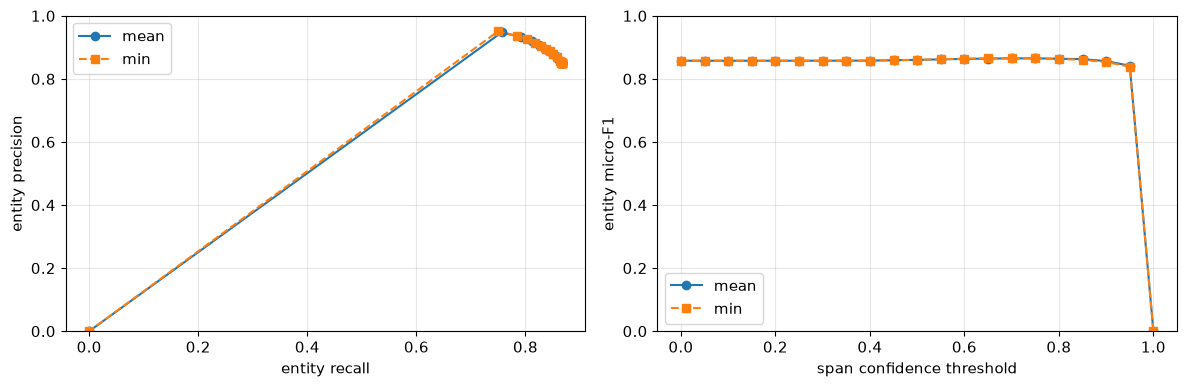

In [34]:
if '6.5' in BONUS_TASKS:
    def filter_by_confidence(tags_list, probs_list, threshold, reduction='mean'):
        if len(tags_list) != len(probs_list):
            raise ValueError('Different number of sentences')
        if reduction not in {'mean', 'min'}:
            raise ValueError('Unknown reduction')
        filtered = []
        for tags, probabilities in zip(tags_list, probs_list):
            if len(tags) != len(probabilities):
                raise ValueError('Different number of words and probabilities')
            kept = []
            for start, end, entity in bio_to_spans(tags):
                values = probabilities[start:end]
                score = sum(values) / len(values) if reduction == 'mean' else min(values)
                if not math.isfinite(score):
                    raise ValueError('Nonfinite confidence')
                if score >= threshold:
                    kept.append((start, end, entity))
            filtered.append(spans_to_bio(kept, len(tags)))
        return filtered

    threshold_curves = {}
    best_thresholds = {}
    for reduction in ['mean', 'min']:
        rows = []
        for threshold in np.linspace(0, 1, 21):
            filtered = filter_by_confidence(val_pred, val_probs, float(threshold), reduction)
            rows.append(dict(threshold=float(threshold), **entity_scores(val_gold, filtered)))
        threshold_curves[reduction] = rows
        best_thresholds[reduction] = max(rows, key=lambda row: (row['f1_micro'], -row['threshold']))
    selected_reduction = max(best_thresholds, key=lambda key: (best_thresholds[key]['f1_micro'],
                                                              -best_thresholds[key]['threshold']))
    selected_threshold = best_thresholds[selected_reduction]['threshold']
    filtered_test = filter_by_confidence(test_pred, test_probs, selected_threshold, selected_reduction)
    threshold_results = dict(selection_split='validation', selected_reduction=selected_reduction,
                              selected_threshold=selected_threshold, best_validation=best_thresholds,
                              test=entity_scores(test_gold, filtered_test))
    print(json.dumps(threshold_results, indent=2))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for reduction, style in [('mean', 'o-'), ('min', 's--')]:
        rows = threshold_curves[reduction]
        axes[0].plot([row['recall'] for row in rows], [row['precision'] for row in rows], style, label=reduction)
        axes[1].plot([row['threshold'] for row in rows], [row['f1_micro'] for row in rows], style, label=reduction)
    axes[0].set_xlabel('entity recall')
    axes[0].set_ylabel('entity precision')
    axes[1].set_xlabel('span confidence threshold')
    axes[1].set_ylabel('entity micro-F1')
    for ax in axes:
        ax.set_ylim(0, 1)
        ax.grid(True, alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Для средней уверенности лучший validation-порог
0.75 дал F1 86.51%,
для минимальной — 0.70 и
86.54%.
При пороге 0 F1 равен 85.76%, поэтому прибавки составляют
0.75 и
0.78 п.п.
По validation выбрано правило min с порогом
0.70; на test оно дало F1
86.84%, изменение относительно исходного test —
+0.67 п.п.
Среднее может скрывать одно слабое слово в длинном спане, а минимум ориентируется
именно на него. Порог удаляет целые спаны, не добавляя новых истинных сущностей,
поэтому recall может только сохраняться или снижаться.
Использована сетка с шагом 0.05; при равном F1 выбирался меньший порог, test
не участвовал в выборе правила.


### Подробные результаты

Дополнительные настройки, аудит данных и результаты бонусов сохраняются отдельно.

In [35]:
additional_metrics = dict(
    stage='cpu-smoke' if SMOKE_MODE else ('fast' if FAST_MODE else 'final'),
    fast_mode=FAST_MODE, seed=SEED, bonus_tasks=sorted(BONUS_TASKS),
    dataset_revision=DATASET_REVISION, dataset_license='CC BY-NC-SA 4.0', model_license='MIT',
    data_audit=data_audit, conversion=conversion_audit, statistics=data_statistics,
    truncation=alignment_audit,
    config=dict(epochs=EPOCHS, learning_rate=LR, batch_size=BATCH_SIZE, max_length=MAX_LENGTH,
                warmup_ratio=0.1, weight_decay=0.01, fp16=device.type == 'cuda'),
    parameters=blocks, history=history, validation=validation_scores,
    validation_per_type=validation_report, error_examples=error_examples,
    ablation_history=ablation_history,
    comparison=model_comparison if '6.2' in BONUS_TASKS else None,
    shifts=shift_results if '6.3' in BONUS_TASKS else None,
    export=export_results if '6.4' in BONUS_TASKS else None,
    thresholds=threshold_results if '6.5' in BONUS_TASKS else None,
    threshold_curves=threshold_curves if '6.5' in BONUS_TASKS else None,
    timings=RUN_TIMES,
)
(ARTIFACTS / 'additional_metrics.json').write_text(
    json.dumps(json_ready(additional_metrics), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Saved additional_metrics.json; stage:', additional_metrics['stage'])

Saved additional_metrics.json; stage: final
